# Email spam classification: feature and model comparison
Compare bag-of-words, word TF-IDF and character TF-IDF with Naive Bayes, logistic regression, linear SVM and Random Forest. Uses the existing SpamAssassin CSV independently of ingestion, the backend and the database.

## 1. Setup and experiment design
From the repository root run `.\.venv\Scripts\python.exe -m pip install -r notebooks/requirements-email.txt`, open this notebook in PyCharm and select `.venv` as the kernel. Choose **Restart Kernel and Run All**. The working directory can be anywhere inside the repository.

Spam is positive (1), legitimate email is 0. Reserve 20% of deduplicated messages for a benchmark. Select candidates using five-fold stratified cross-validation on the model-training partition, then use a separate calibration partition to select an operating threshold without touching the benchmark. The predeclared model-selection metric remains spam F1; the threshold policy requires at least 95% spam recall and at most 2% legitimate-email false-positive rate. Report precision, recall, accuracy, and false-positive rate too: hiding legitimate email is a different cost from missing spam. All feature learning is inside CV pipelines.

**Evaluation history:** the benchmark partition was already inspected in the first version of this notebook. Reusing it supports comparisons but does not create a fresh, independent final test. Do not change random seeds to chase a better score. The optional external evaluation section supports a separate, labeled set of recent inbox messages that has never informed training or selection. No current-inbox accuracy is claimed without that evidence.


In [2]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import re
import unicodedata
import tempfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, PrecisionRecallDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import Pipeline

SEED = 42
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pipeline/config.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the SafeFlow AI repository.")
"""Versioned email input contract shared by training and serving."""

import re
import unicodedata

PREPROCESSING_VERSION = "email-text-v1"


def normalize_text(value: str) -> str:
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(value))).strip()


def email_text(subject: str, body: str) -> str:
    if not isinstance(subject, str) or not isinstance(body, str):
        raise TypeError("Email subject and body must be strings.")
    return normalize_text(f"{normalize_text(subject)} {normalize_text(body)}")


def spam_scores(model, texts):
    """Return spam-oriented scores and their meaning, without calibration claims."""
    if hasattr(model, "predict_proba"):
        return (
            model.predict_proba(texts)[:, list(model.classes_).index(1)],
            "uncalibrated_probability",
        )
    scores = model.decision_function(texts)
    if model.classes_[1] != 1:
        scores = -scores
    return scores, "decision_margin"


DATA_PATH = ROOT / "data/processed/messages/spamassassin_emails_cleaned.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Missing cleaned email dataset: {DATA_PATH}")
versions = {name: importlib.metadata.version(name)
            for name in ["pandas", "numpy", "scikit-learn", "matplotlib", "joblib", "scipy"]}
print("Python:", platform.python_version())
print("Package versions:", versions)
print("Dataset SHA-256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())


Python: 3.13.15
Package versions: {'pandas': '3.0.5', 'numpy': '2.5.3', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.1', 'joblib': '1.6.0', 'scipy': '1.18.1'}
Dataset SHA-256: 9df96a31df8e13669720ef20754fe511388193c193332d9e5f88b0dd46037101


## 2. Validate the dataset
Read only subject, body, and label into the experiment. Never train on `source_folder`, file names, IDs, or other dataset metadata: folder names encode the target. Rebuild input from subject and body instead of trusting the undocumented `text` column. Empty strings are preserved so literal text such as "NA" is not silently interpreted as missing. Only aggregate information is displayed, not private email content.


In [3]:
raw = pd.read_csv(DATA_PATH, keep_default_na=False)
required = {"subject", "body", "label"}
if not required.issubset(raw.columns):
    raise ValueError(f"Missing columns: {required - set(raw.columns)}")
if raw.empty or not set(raw["label"]).issubset({"legitimate", "spam"}):
    raise ValueError("Expected a nonempty dataset with legitimate/spam labels only.")
display(raw["label"].value_counts().rename("rows").to_frame())
display(raw[["subject", "body"]].apply(lambda c: c.str.strip().eq("").sum())
        .rename("empty values").to_frame())


,rows
label,
legitimate,2722
spam,1796


,empty values
subject,15
body,107


## 3. Prepare text and remove duplicate leakage
Use Unicode normalization and whitespace cleanup while retaining punctuation, numbers, and stop words that may carry spam signals. Deduplicate using the normalized **body**, falling back to subject for bodyless messages; this also prevents the same body with a different subject from crossing splits. Case and whitespace differences are collapsed. Remove all copies of groups with contradictory labels rather than guessing the correct label; keep one representative of each remaining group.

This deterministic data-quality policy is defined before splitting. It is conservative and changes the evaluation population to unique content. It does not identify all near-duplicate campaigns, HTML variants, or forwarded messages, so residual similarity can still inflate scores.


In [3]:
data = raw[["subject", "body", "label"]].copy()
data["subject"] = data["subject"].map(normalize_text)
data["body"] = data["body"].map(normalize_text)
data["input_text"] = [email_text(s, b) for s, b in zip(data.subject, data.body)]
empty_count = int(data.input_text.eq("").sum())
data = data.loc[data.input_text.ne("")].copy()
data["duplicate_key"] = data.body.where(data.body.ne(""), data.subject).str.casefold()
conflicts = data.groupby("duplicate_key")["label"].nunique()
conflicting_keys = conflicts[conflicts > 1].index
conflicting_rows = int(data.duplicate_key.isin(conflicting_keys).sum())
data = data.loc[~data.duplicate_key.isin(conflicting_keys)].copy()
duplicate_count = int(data.duplicated("duplicate_key").sum())
data = data.drop_duplicates("duplicate_key").reset_index(drop=True)
data["target"] = data.label.map({"legitimate": 0, "spam": 1})
assert data.duplicate_key.is_unique
assert set(data.target) == {0, 1}
print({"original_rows": len(raw), "empty_removed": empty_count,
       "conflicting_rows_removed": conflicting_rows,
       "duplicate_rows_removed": duplicate_count, "usable_rows": len(data)})
display(data.label.value_counts().rename("unique messages").to_frame())


{'original_rows': 4518, 'empty_removed': 0, 'conflicting_rows_removed': 3, 'duplicate_rows_removed': 161, 'usable_rows': 4354}


,unique messages
label,
legitimate,2712
spam,1642


## 4. Reserve the test set
Stratification approximately preserves class proportions. A fixed seed and dataset fingerprint make the split reproducible. The test set is excluded from vocabulary learning, cross-validation, and model selection. This random corpus split measures same-source performance, not performance on future emails.


In [4]:
train, test = train_test_split(data, test_size=0.20, stratify=data.target,
                               random_state=SEED)
model_train, calibration = train_test_split(train, test_size=0.20,
                                             stratify=train.target,
                                             random_state=SEED)
assert set(train.duplicate_key).isdisjoint(test.duplicate_key)
assert set(model_train.duplicate_key).isdisjoint(calibration.duplicate_key)
assert train.target.value_counts().min() >= 5
X_model_train, y_model_train = model_train.input_text, model_train.target
X_calibration, y_calibration = calibration.input_text, calibration.target
X_train, y_train = train.input_text, train.target
X_test, y_test = test.input_text, test.target
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()})
        .rename(index={0: "legitimate", 1: "spam"}))


,train,test
target,,
legitimate,2169,543
spam,1314,328


## 5. Compare features and models using training data only
| Representation | What it captures | Candidates |
|---|---|---|
| Bag-of-words | Raw word/unigram and phrase/bigram counts | Multinomial Naive Bayes |
| Word TF-IDF | Frequency weighted by rarity across training documents | Complement NB, logistic regression, linear SVM, Random Forest |
| Character TF-IDF | 3-5 character sequences within word boundaries | Linear SVM |

Character fragments are worth testing for spelling variants and obfuscation, but this experiment cannot establish robustness to all attacks. A word-SVM variant with English stop-word removal tests that preprocessing choice on identical folds. Lowercasing is done in the vectorizers. We do not automatically remove punctuation, digits or apply stemming: these can erase useful signals, and the character model deliberately retains them. Stemming/lemmatization would be additional validation experiments, not mandatory cleaning.

**Word embeddings** are another candidate, not an automatic upgrade. They require a specified pretrained model, its language/domain coverage and an additional dependency/download. This notebook first establishes reproducible local sparse-text baselines. A future embedding experiment should use the same training folds, document model provenance and reserve a new external test set.

Compare nine bounded configurations: one BoW NB, two word Complement NB smoothing values, two word logistic-regression regularization strengths, word SVM with/without stop words, character SVM, and a 150-tree Random Forest baseline. This is a practical comparison, not an exhaustive search or equal tuning budget for every family. RF uses a smaller vocabulary to bound cost. Five-fold CV selects by mean spam F1 and reports variability and runtime. Feature extraction is cached in a temporary directory for this run only, so candidates sharing a vectorizer reuse training-fold features without sharing information across folds. `n_jobs=1` bounds memory and CPU use. Expect several minutes.


In [5]:
word_tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2),
    min_df=2, max_features=30000, sublinear_tf=True)
parameters = [
    {"features": [CountVectorizer(lowercase=True, ngram_range=(1, 2),
                                  min_df=2, max_features=30000)],
     "classifier": [MultinomialNB(alpha=1.0)]},
    {"features": [word_tfidf], "classifier": [ComplementNB()],
     "classifier__alpha": [0.1, 0.5]},
    {"features": [word_tfidf],
     "classifier": [LogisticRegression(max_iter=2000, solver="liblinear", random_state=SEED)],
     "classifier__C": [1.0, 10.0]},
    {"features": [word_tfidf,
                  TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                      max_features=30000, sublinear_tf=True, stop_words="english")],
     "classifier": [LinearSVC(C=1.0, max_iter=5000, random_state=SEED)]},
    {"features": [TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                      min_df=2, max_features=40000, sublinear_tf=True)],
     "classifier": [LinearSVC(C=1.0, max_iter=5000, random_state=SEED)]},
    {"features": [TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                      max_features=10000, sublinear_tf=True)],
     "classifier": [RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                         max_features="sqrt", random_state=SEED, n_jobs=1)]},
]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
with tempfile.TemporaryDirectory(prefix="safeflow-email-cv-") as cache_directory:
    pipeline = Pipeline([("features", word_tfidf), ("classifier", ComplementNB())],
                        memory=cache_directory)
    search = GridSearchCV(pipeline, parameters, cv=cv,
        scoring={"f1": "f1", "precision": "precision", "recall": "recall", "accuracy": "accuracy"},
        refit="f1", n_jobs=1, error_score="raise", return_train_score=False, verbose=2)
    search.fit(X_model_train, y_model_train)
    best_model = search.best_estimator_
    calibration_scores, score_type = spam_scores(best_model, X_calibration)
    threshold_candidates = np.unique(np.r_[0.0, calibration_scores])
    threshold_rows = []
    for threshold in threshold_candidates:
        calibration_prediction = (calibration_scores >= threshold).astype(int)
        threshold_rows.append({
            "threshold": float(threshold),
            "accuracy": accuracy_score(y_calibration, calibration_prediction),
            "spam_recall": recall_score(y_calibration, calibration_prediction, zero_division=0),
            "false_positive_rate": float(np.mean(
                calibration_prediction[np.asarray(y_calibration) == 0] == 1)),
        })
    threshold_results = pd.DataFrame(threshold_rows)
    eligible = threshold_results[
        (threshold_results.spam_recall >= 0.95)
        & (threshold_results.false_positive_rate <= 0.02)
    ]
    if eligible.empty:
        raise RuntimeError("Calibration could not meet the spam recall/FPR operating policy.")
    SPAM_THRESHOLD = float(eligible.sort_values(
        ["accuracy", "threshold"], ascending=[False, False]).iloc[0].threshold)
    best_model.fit(X_train, y_train)
    print(f"Selected operating threshold: {SPAM_THRESHOLD:.4f} ({score_type})")
    best_model.memory = None  # inference does not depend on a temporary cache
cv_results = pd.DataFrame(search.cv_results_)
cv_results["model"] = cv_results.params.map(lambda p: type(p["classifier"]).__name__)
cv_results["representation"] = cv_results.params.map(
    lambda p: f"{type(p['features']).__name__} / {p['features'].analyzer} / stop_words={p['features'].stop_words}")
columns = ["model", "representation", "params", "mean_test_f1", "std_test_f1",
           "mean_test_precision", "mean_test_recall", "mean_test_accuracy",
           "mean_fit_time", "rank_test_f1"]
display(cv_results[columns].sort_values("rank_test_f1").reset_index(drop=True))
print("Selected parameters:", search.best_params_)
print(f"Selected mean CV spam F1: {search.best_score_:.4f}")


Fitting 5 folds for each of 9 candidates, totalling 45 fits


[CV] END classifier=MultinomialNB(), features=CountVectorizer(max_features=30000, min_df=2, ngram_range=(1, 2)); total time=   2.4s


[CV] END classifier=MultinomialNB(), features=CountVectorizer(max_features=30000, min_df=2, ngram_range=(1, 2)); total time=   2.7s


[CV] END classifier=MultinomialNB(), features=CountVectorizer(max_features=30000, min_df=2, ngram_range=(1, 2)); total time=   2.5s


[CV] END classifier=MultinomialNB(), features=CountVectorizer(max_features=30000, min_df=2, ngram_range=(1, 2)); total time=   2.2s


...

[CV] END classifier=RandomForestClassifier(min_samples_leaf=2, n_estimators=150, n_jobs=1,
                       random_state=42), features=TfidfVectorizer(max_features=10000, min_df=2, ngram_range=(1, 2),
                sublinear_tf=True); total time=   3.6s


[CV] END classifier=RandomForestClassifier(min_samples_leaf=2, n_estimators=150, n_jobs=1,
                       random_state=42), features=TfidfVectorizer(max_features=10000, min_df=2, ngram_range=(1, 2),
                sublinear_tf=True); total time=   3.5s


[CV] END classifier=RandomForestClassifier(min_samples_leaf=2, n_estimators=150, n_jobs=1,
                       random_state=42), features=TfidfVectorizer(max_features=10000, min_df=2, ngram_range=(1, 2),
                sublinear_tf=True); total time=   3.5s


,model,representation,params,mean_test_f1,std_test_f1,mean_test_precision,mean_test_recall,mean_test_accuracy,mean_fit_time,rank_test_f1
0,LinearSVC,TfidfVectorizer / char_wb / stop_words=None,"{'classifier': LinearSVC(max_iter=5000, random...",0.980615,0.003860,0.979561,0.981729,0.985358,8.484249,1
1,LinearSVC,TfidfVectorizer / word / stop_words=None,"{'classifier': LinearSVC(max_iter=5000, random...",0.979424,0.005776,0.981054,0.977924,0.984496,0.194619,2
2,LinearSVC,TfidfVectorizer / word / stop_words=english,"{'classifier': LinearSVC(max_iter=5000, random...",0.979089,0.006018,0.979605,0.978687,0.984208,2.124797,3
3,LogisticRegression,TfidfVectorizer / word / stop_words=None,{'classifier': LogisticRegression(max_iter=200...,0.975534,0.005851,0.978681,0.972586,0.981624,0.318792,4
4,ComplementNB,TfidfVectorizer / word / stop_words=None,"{'classifier': ComplementNB(), 'classifier__al...",0.968061,0.009035,0.977517,0.958889,0.976167,2.446777,5
5,ComplementNB,TfidfVectorizer / word / stop_words=None,"{'classifier': ComplementNB(), 'classifier__al...",0.963981,0.010555,0.978807,0.949752,0.973295,0.205850,6
6,RandomForestClassifier,TfidfVectorizer / word / stop_words=None,{'classifier': RandomForestClassifier(min_samp...,0.963003,0.004049,0.965078,0.961173,0.972150,3.445467,7
7,MultinomialNB,CountVectorizer / word / stop_words=None,"{'classifier': MultinomialNB(), 'features': Co...",0.956528,0.009401,0.983218,0.931489,0.968127,2.265157,8
8,LogisticRegression,TfidfVectorizer / word / stop_words=None,{'classifier': LogisticRegression(max_iter=200...,0.956263,0.014015,0.978454,0.935286,0.967839,0.310697,9


Selected parameters: {'classifier': LinearSVC(max_iter=5000, random_state=42), 'features': TfidfVectorizer(analyzer='char_wb', max_features=40000, min_df=2,
                ngram_range=(3, 5), sublinear_tf=True)}
Selected mean CV spam F1: 0.9806


## 6. Reused benchmark evaluation and confusion matrix
The selected pipeline was automatically refitted on the complete training partition, never on the test partition. Compare it with an always-legitimate majority baseline. Accuracy alone can conceal missed spam; report both classes and spam precision, recall, F1 and average precision (AP). AP summarizes ranking quality across thresholds; SVM decision margins are ranking scores, not probabilities. Other candidates expose probabilities, which are not guaranteed to be calibrated. The helpers report the score type explicitly.

In the confusion matrix, rows are actual labels and columns are predictions: top-right = legitimate email incorrectly flagged (false positive); bottom-left = missed spam (false negative). The normalized matrix shows proportions within each actual class. This partition has been viewed before: use these results as a development benchmark, not a new final estimate of inbox performance. Do not choose a model or threshold using these results.


Ranking score type: decision_margin


,accuracy,spam_precision,spam_recall,spam_f1,false_positive_rate
majority_baseline,0.623421,0.000000,0.000000,0.000000,0.000000
selected_model,0.983927,0.975758,0.981707,0.978723,0.014733


,precision,recall,f1-score,support
legitimate,0.988909,0.985267,0.987085,543.000000
spam,0.975758,0.981707,0.978723,328.000000
accuracy,0.983927,0.983927,0.983927,0.983927
macro avg,0.982334,0.983487,0.982904,871.000000
weighted avg,0.983957,0.983927,0.983936,871.000000


Spam average precision: 0.9981


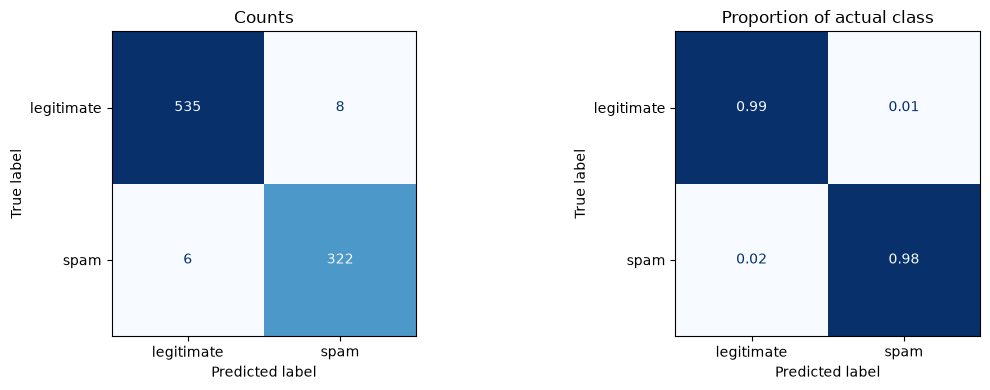

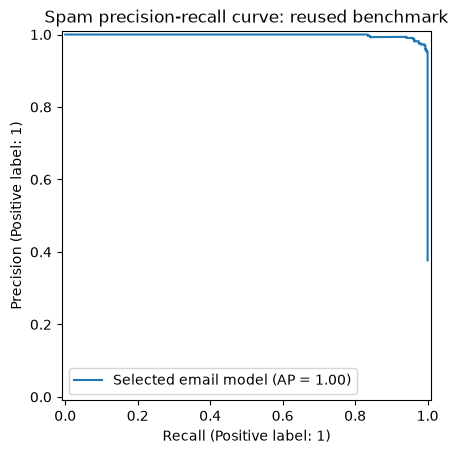

Correct legitimate: 535; false spam alarms: 8; missed spam: 6; correct spam: 322


In [6]:
default_predicted = best_model.predict(X_test)
spam_score, score_type = spam_scores(best_model, X_test)
predicted = (spam_score >= SPAM_THRESHOLD).astype(int)
print("Ranking score type:", score_type)
print(f"Operating threshold: {SPAM_THRESHOLD:.4f}")
baseline = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
baseline_predicted = baseline.predict(np.zeros((len(y_test), 1)))
def metrics(y, prediction):
    return {"accuracy": accuracy_score(y, prediction),
            "spam_precision": precision_score(y, prediction, zero_division=0),
            "spam_recall": recall_score(y, prediction, zero_division=0),
            "spam_f1": f1_score(y, prediction, zero_division=0),
            "false_positive_rate": float(np.mean(np.asarray(prediction)[np.asarray(y) == 0] == 1))}
results = pd.DataFrame({"majority_baseline": metrics(y_test, baseline_predicted),
                        "selected_model": metrics(y_test, predicted)}).T
display(results)
report = classification_report(y_test, predicted, labels=[0, 1],
    target_names=["legitimate", "spam"], output_dict=True, zero_division=0)
display(pd.DataFrame(report).T)
print(f"Spam average precision: {average_precision_score(y_test, spam_score):.4f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, normalization, title in zip(axes, [None, "true"], ["Counts", "Proportion of actual class"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0, 1],
        display_labels=["legitimate", "spam"], normalize=normalization,
        values_format="d" if normalization is None else ".2f", cmap="Blues", ax=ax,
        colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()
PrecisionRecallDisplay.from_predictions(y_test, spam_score, name="Selected email model")
plt.title("Spam precision-recall curve: reused benchmark")
plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
print(f"Correct legitimate: {tn}; false spam alarms: {fp}; missed spam: {fn}; correct spam: {tp}")


## 7. Predict a new email
Supply subject and body as plain strings. This helper applies the same text preparation as training, then uses the fitted vectorizer and classifier. Synthetic examples illustrate usage, not an additional quality benchmark. Empty input is rejected. A spam score is a model estimate, not a certainty or a phishing verdict.


In [7]:
def predict_email(subject, body):
    if not isinstance(subject, str) or not isinstance(body, str):
        raise TypeError("Subject and body must be strings; use an empty string for missing fields.")
    text = email_text(subject, body)
    if not text:
        raise ValueError("Provide a nonempty email subject or body.")
    scores, kind = spam_scores(best_model, [text])
    label = int(scores[0] >= SPAM_THRESHOLD)
    return {"prediction": "spam" if label else "legitimate",
            "spam_score": float(scores[0]), "score_type": kind}

display(predict_email("Project meeting", "Can we review the project tomorrow at ten?"))
display(predict_email("Claim your prize now", "Congratulations! Click now to claim your free cash prize."))


{'prediction': 'spam',
 'spam_score': 0.32430048939922856,
 'score_type': 'decision_margin'}

{'prediction': 'spam',
 'spam_score': 1.4450248209404908,
 'score_type': 'decision_margin'}

## 8. Export the evaluated pipeline
`SAVE_ARTIFACTS = True` writes the fitted vectorizer/classifier and a versioned manifest to `../../ml/artifacts/email_spam`. Set it to False to disable export. These local artifacts are excluded from Git. Only the training partition has been fitted; neither the existing benchmark nor the later synthetic set is used to fit the artifact.

The manifest records dependency versions, preprocessing version, class mapping, dataset hash, benchmark metrics and artifact checksum. These artifacts are available for a future backend integration by the team. Any consumer must apply the same `email_text` preprocessing defined in this notebook and validate artifact compatibility. The notebook does not require backend Python modules. No probabilities are inferred from SVM margins.

This model remains experimental: the synthetic set exposed 16 legitimate emails incorrectly flagged out of 20. Joblib files must come from a trusted source; the checksum detects mismatched files but does not make an untrusted file safe. Re-running export replaces the previous artifact and manifest.


In [8]:
SAVE_ARTIFACTS = True
if SAVE_ARTIFACTS:
    output = ROOT / "ml/artifacts/email_spam"
    output.mkdir(parents=True, exist_ok=True)
    artifact_tmp = output / "pipeline.joblib.tmp"
    joblib.dump(best_model, artifact_tmp, compress=3)
    artifact_hash = hashlib.sha256(artifact_tmp.read_bytes()).hexdigest()
    metadata = {
        "artifact_format_version": 1,
        "artifact_sha256": artifact_hash,
        "model_version": f"email-spam-{artifact_hash[:12]}",
        "preprocessing_version": PREPROCESSING_VERSION,
        "dataset_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
        "seed": SEED, "versions": versions, "python": platform.python_version(),
        "train_rows": len(train), "test_rows": len(test),
        "selected_parameters": {k: str(v) for k, v in search.best_params_.items()},
        "cv_spam_f1": search.best_score_,
        "spam_threshold": SPAM_THRESHOLD,
        "threshold_policy": "maximize calibration accuracy with spam recall >= 0.95 and false-positive rate <= 0.02",
        "benchmark_metrics": metrics(y_test, predicted),
        "evaluation_status": "Previously inspected corpus benchmark; no independent inbox evaluation",
        "score_type": score_type,
        "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]],
        "preprocessing": "NFKC, collapse whitespace; concatenate subject and body",
        "class_mapping": {"0": "legitimate", "1": "spam"},
    }
    metadata_tmp = output / "metadata.json.tmp"
    metadata_tmp.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    artifact_tmp.replace(output / "pipeline.joblib")
    metadata_tmp.replace(output / "metadata.json")
    print("Saved", metadata["model_version"], "to", output)
else:
    print("Export disabled; the fitted model remains available in this kernel.")


Saved email-spam-284d7de725b7 to C:\Users\eserbanescu\OneDrive - ENDAVA\Desktop\SafeFlow AI\ml\artifacts\email_spam


## 9. Interpretation, limitations, and next steps
- This benchmark predicts **spam versus legitimate**, not phishing, fraud, or general email safety.
- Corpus artifacts, signatures and near-duplicate campaigns may make random-split results optimistic. Evaluate on independent, recent emails and preferably split by campaign or time before deployment.
- Inspect false-positive and false-negative patterns privately. Further changes must use training-only validation and a fresh final test set if this test has informed decisions.
- The original email parser can omit HTML-only multipart bodies. Subject-only examples therefore remain; assess MIME/HTML extraction before integrating real incoming mail.
- Deduplication removes repeated bodies, including potentially distinct emails with identical short bodies. Document this tradeoff when reporting metrics.
- Decide the acceptable false-positive cost with the team before changing the classification threshold; use validation data and assess calibration if probabilities will drive decisions.

### References
- [scikit-learn: common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: text feature extraction and model selection](https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_text_feature_extraction.html)

### Testing on incoming inbox email
Collect a representative, manually labeled sample including normal correspondence, newsletters, transactional mail and spam. Keep actual class proportions instead of balancing the test artificially. Match the inference preprocessing: MIME-decoded subject and body, with a consistent HTML-to-text policy. Raw `.eml` files or HTML markup are not the input contract of this notebook.

Freeze the pipeline before scoring that set. Report legitimate-email false-positive rate as well as spam precision/recall, sample size and collection period. Start by showing predictions for review; choose automatic filtering thresholds from separate training/validation data once the acceptable false-positive cost is defined. Do not interpret a margin as a confidence percentage. Calibrate probabilities on training-only folds if probabilities are needed. Evaluate later time periods and new senders/campaigns, and collect corrections to detect drift.

- [scikit-learn: text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction)
- [scikit-learn: probability calibration](https://scikit-learn.org/stable/modules/calibration.html)


## 10. Optional independent inbox evaluation
Set `EXTERNAL_CSV` to a local CSV path with `subject`, `body`, and `label` (`spam` or `legitimate`). This cell does **not** train, tune or download messages. It rejects empty input, unknown labels, duplicate normalized bodies/subject fallbacks, and overlap with the source corpus so these problems cannot silently inflate the result. Near-duplicate campaigns still require a separate review. Use both classes and enough examples of each to estimate their error rates; small sets have high uncertainty. Relative paths resolve from the project root.

Keep personal inbox datasets outside tracked project files. A set used repeatedly to guide development becomes validation data and must be replaced with a fresh final evaluation set.


In [9]:
EXTERNAL_CSV = None  # e.g. Path(r"C:/private-data/labeled_inbox.csv")
if EXTERNAL_CSV is None:
    print("No external inbox dataset supplied; current-inbox accuracy is not measured.")
else:
    external_path = Path(EXTERNAL_CSV).expanduser()
    if not external_path.is_absolute():
        external_path = ROOT / external_path
    external = pd.read_csv(external_path, keep_default_na=False)
    if not {"subject", "body", "label"}.issubset(external.columns):
        raise ValueError("External CSV needs subject, body and label columns.")
    if set(external.label) != {"legitimate", "spam"}:
        raise ValueError("External evaluation requires both legitimate and spam labels, and no unknown labels.")
    ext_subject = external.subject.map(normalize_text)
    ext_body = external.body.map(normalize_text)
    ext_text = pd.Series([email_text(s, b) for s, b in zip(ext_subject, ext_body)])
    ext_keys = ext_body.where(ext_body.ne(""), ext_subject).str.casefold()
    source_body = raw.body.map(normalize_text)
    source_subject = raw.subject.map(normalize_text)
    source_keys = source_body.where(source_body.ne(""), source_subject).str.casefold()
    if ext_text.eq("").any() or ext_keys.duplicated().any():
        raise ValueError("Remove empty messages and duplicate content before evaluating.")
    if set(ext_keys).intersection(source_keys):
        raise ValueError("External content overlaps the original corpus; use independent messages.")
    ext_y = external.label.map({"legitimate": 0, "spam": 1})
    ext_prediction = best_model.predict(ext_text)
    print("External rows:", len(external))
    display(external.label.value_counts().rename("rows").to_frame())
    display(pd.Series(metrics(ext_y, ext_prediction), name="external inbox metrics").to_frame())
    ConfusionMatrixDisplay.from_predictions(ext_y, ext_prediction, labels=[0, 1],
        display_labels=["legitimate", "spam"], cmap="Blues", colorbar=False)
    plt.title("Independent inbox evaluation")
    plt.show()


No external inbox dataset supplied; current-inbox accuracy is not measured.


## 11. Additional synthetic test dataset (separate from the existing split)
The repository now includes `../../data/evaluation/emails/synthetic_emails.csv`: **40 newly authored English emails, 20 legitimate and 20 spam**, with exactly the same CSV columns as the training source. See its adjacent README for provenance and labeling assumptions. It contains routine messages, opt-in promotions, security notices, unsolicited promotions, scams and obfuscated spam. Reserved example domains avoid real recipients or live links.

This small, balanced set checks behavior on new authored examples. It is **not representative of real inbox traffic**, and its accuracy is not a deployment estimate. Labels describe the intended scenario; some distinctions (such as consent or a genuine security alert) need context beyond text.

The existing training partition, cross-validation selection and 871-row corpus benchmark are unchanged. This new CSV is loaded only here, after training. There are no fit, tuning or threshold-selection calls below. Do not adjust labels/examples or the model to improve this score. The optional external inbox evaluation above remains available for genuinely collected data.


In [10]:
SYNTHETIC_CSV = ROOT / "data/evaluation/emails/synthetic_emails.csv"
synthetic = pd.read_csv(SYNTHETIC_CSV, keep_default_na=False)
if list(synthetic.columns) != list(raw.columns):
    raise ValueError("Synthetic CSV must have the same columns and order as the training CSV.")
if synthetic.empty or set(synthetic.label) != {"legitimate", "spam"}:
    raise ValueError("Synthetic CSV must contain both legitimate and spam labels only.")
if not synthetic.message_id.is_unique or synthetic.message_id.eq("").any():
    raise ValueError("Synthetic message IDs must be nonempty and unique.")
syn_subject = synthetic.subject.map(normalize_text)
syn_body = synthetic.body.map(normalize_text)
syn_text = pd.Series([email_text(s, b) for s, b in zip(syn_subject, syn_body)])
syn_keys = syn_body.where(syn_body.ne(""), syn_subject).str.casefold()
original_body = raw.body.map(normalize_text)
original_subject = raw.subject.map(normalize_text)
original_keys = original_body.where(original_body.ne(""), original_subject).str.casefold()
if syn_text.eq("").any() or syn_keys.duplicated().any():
    raise ValueError("Synthetic dataset has empty or duplicated content.")
if set(syn_keys).intersection(original_keys):
    raise ValueError("Synthetic dataset overlaps the original corpus.")
if set(synthetic.message_id.astype(str)).intersection(raw.message_id.astype(str)):
    raise ValueError("Synthetic message IDs overlap the source corpus.")
print("New examples:", len(synthetic))
print("Synthetic CSV SHA-256:", hashlib.sha256(SYNTHETIC_CSV.read_bytes()).hexdigest())
display(synthetic.label.value_counts().rename("examples").to_frame())


New examples: 40
Synthetic CSV SHA-256: dc83c753df893b562a0cf5ebc866ad0c1ea6465c4f95a73c9c4fb9f397df65c2


,examples
label,
legitimate,20
spam,20


## 12. Predict and measure performance on the additional dataset
Apply the already fitted model to subject + body. The `label`, `text`, sender, source and other metadata are excluded from the features. Report accuracy, spam precision/recall/F1, false-positive rate, average precision, class support and a confusion matrix. The bar chart is a descriptive summary, not a comparison used for model selection. All values refer only to these 40 synthetic examples.

A false positive is a legitimate email predicted as spam; a false negative is spam predicted as legitimate. A decision margin is not a probability, and score magnitudes cannot be compared across different model families.


Synthetic evaluation only; score type: decision_margin


,synthetic evaluation
accuracy,0.600000
spam_precision,0.555556
spam_recall,1.000000
spam_f1,0.714286
false_positive_rate,0.800000
average_precision,0.974585


,precision,recall,f1-score,support
legitimate,1.000000,0.2,0.333333,20.0
spam,0.555556,1.0,0.714286,20.0
accuracy,0.600000,0.6,0.600000,0.6
macro avg,0.777778,0.6,0.523810,40.0
weighted avg,0.777778,0.6,0.523810,40.0


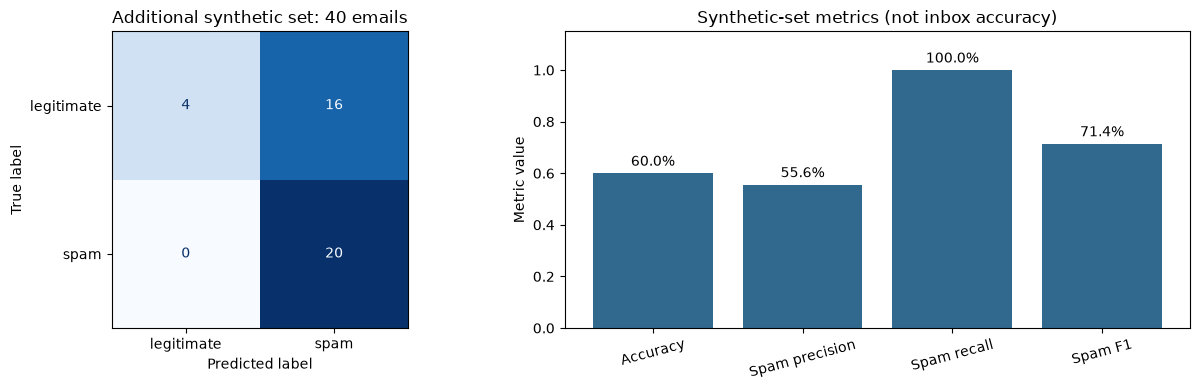

All additional emails and their predictions (full results remain in synthetic_predictions):


,message_id,subject,body,actual_label,prediction,spam_score,score_type,correct
0,SYNTH-001,Review notes for the release,I have added comments to the release checklist. Please review the two open questions before our meeting on Wednesday.,legitimate,legitimate,-0.067591,decision_margin,True
1,SYNTH-002,Your library reservation is ready,The book you reserved is available at the central library. Please collect it within seven days and bring your member...,legitimate,spam,0.564979,decision_margin,False
2,SYNTH-003,Receipt for your monthly subscription,Thank you for your payment of 12.00 EUR. Your subscription renewal is complete. This receipt is for your records; no...,legitimate,spam,0.727625,decision_margin,False
3,SYNTH-004,Password reset requested,"You requested a password reset a moment ago. If this was not you, ignore this message. You can also open the app dir...",legitimate,spam,0.262337,decision_margin,False
4,SYNTH-005,Lunch tomorrow?,Are you free for lunch around noon? I can meet you at the cafe near the office. Let me know if another time works be...,legitimate,legitimate,-0.001312,decision_margin,True
5,SYNTH-006,Security notice: new sign-in,"We recorded a sign-in from a new device. If you recognize it, no action is needed. Otherwise open your account setti...",legitimate,spam,0.159600,decision_margin,False
6,SYNTH-007,Your package delivery is scheduled,Your order is scheduled for delivery tomorrow between 10:00 and 14:00. Track it from your order history. There is no...,legitimate,spam,0.248421,decision_margin,False
7,SYNTH-008,Invoice correction for April,Please disregard the duplicate invoice sent yesterday. The corrected invoice matches our purchase order for 340 EUR....,legitimate,spam,0.360439,decision_margin,False
8,SYNTH-009,Weekend sale for newsletter subscribers,You subscribed to our bookstore newsletter. This weekend selected novels are 20 percent off. Browse at https://books...,legitimate,legitimate,-0.149367,decision_margin,True
9,SYNTH-010,Doctor appointment reminder,"This is a reminder of your appointment on Thursday at 09:30. Please arrive ten minutes early. To reschedule, call th...",legitimate,spam,0.545008,decision_margin,False


In [11]:
syn_y = synthetic.label.map({"legitimate": 0, "spam": 1})
syn_scores, syn_score_type = spam_scores(best_model, syn_text)
syn_default_prediction = best_model.predict(syn_text)
syn_prediction = (syn_scores >= SPAM_THRESHOLD).astype(int)
syn_metrics = metrics(syn_y, syn_prediction)
syn_metrics["average_precision"] = average_precision_score(syn_y, syn_scores)
synthetic_predictions = synthetic[["message_id", "subject", "body", "label"]].copy()
synthetic_predictions = synthetic_predictions.rename(columns={"label": "actual_label"})
synthetic_predictions["prediction"] = pd.Series(syn_prediction).map({0: "legitimate", 1: "spam"})
synthetic_predictions["spam_score"] = syn_scores
synthetic_predictions["score_type"] = syn_score_type
synthetic_predictions["correct"] = synthetic_predictions.actual_label.eq(synthetic_predictions.prediction)
print("Synthetic evaluation only; score type:", syn_score_type)
display(pd.Series(syn_metrics, name="synthetic evaluation").to_frame())
display(pd.DataFrame(classification_report(syn_y, syn_prediction, labels=[0, 1],
    target_names=["legitimate", "spam"], output_dict=True, zero_division=0)).T)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ConfusionMatrixDisplay.from_predictions(syn_y, syn_prediction, labels=[0, 1],
    display_labels=["legitimate", "spam"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Additional synthetic set: {len(synthetic)} emails")
metric_names = ["accuracy", "spam_precision", "spam_recall", "spam_f1"]
values = [syn_metrics[name] for name in metric_names]
bars = axes[1].bar(["Accuracy", "Spam precision", "Spam recall", "Spam F1"], values, color="#31688e")
axes[1].set_ylim(0, 1.15)
axes[1].set_ylabel("Metric value")
axes[1].set_title("Synthetic-set metrics (not inbox accuracy)")
axes[1].bar_label(bars, labels=[f"{value:.1%}" for value in values], padding=3)
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()
print("All additional emails and their predictions (full results remain in synthetic_predictions):")
with pd.option_context("display.max_rows", 50, "display.max_colwidth", 120):
    display(synthetic_predictions)


## 13. Plot example emails and predictions
The six cards show the full authored input subject/body, actual class, prediction and model score. To make errors visible, select up to two incorrect predictions first, then two examples from each actual class where possible, then fill in CSV order. This display selection happens after evaluation and does not change any metric. The table above includes **every** example, so correct cases and mistakes remain reviewable.

Green cards are correct; red cards are incorrect. Inspect errors to understand limitations, but use a different validation dataset for subsequent development rather than tuning to this set. The full text displayed here is synthetic; take care with personal inbox content if adapting these visualizations.


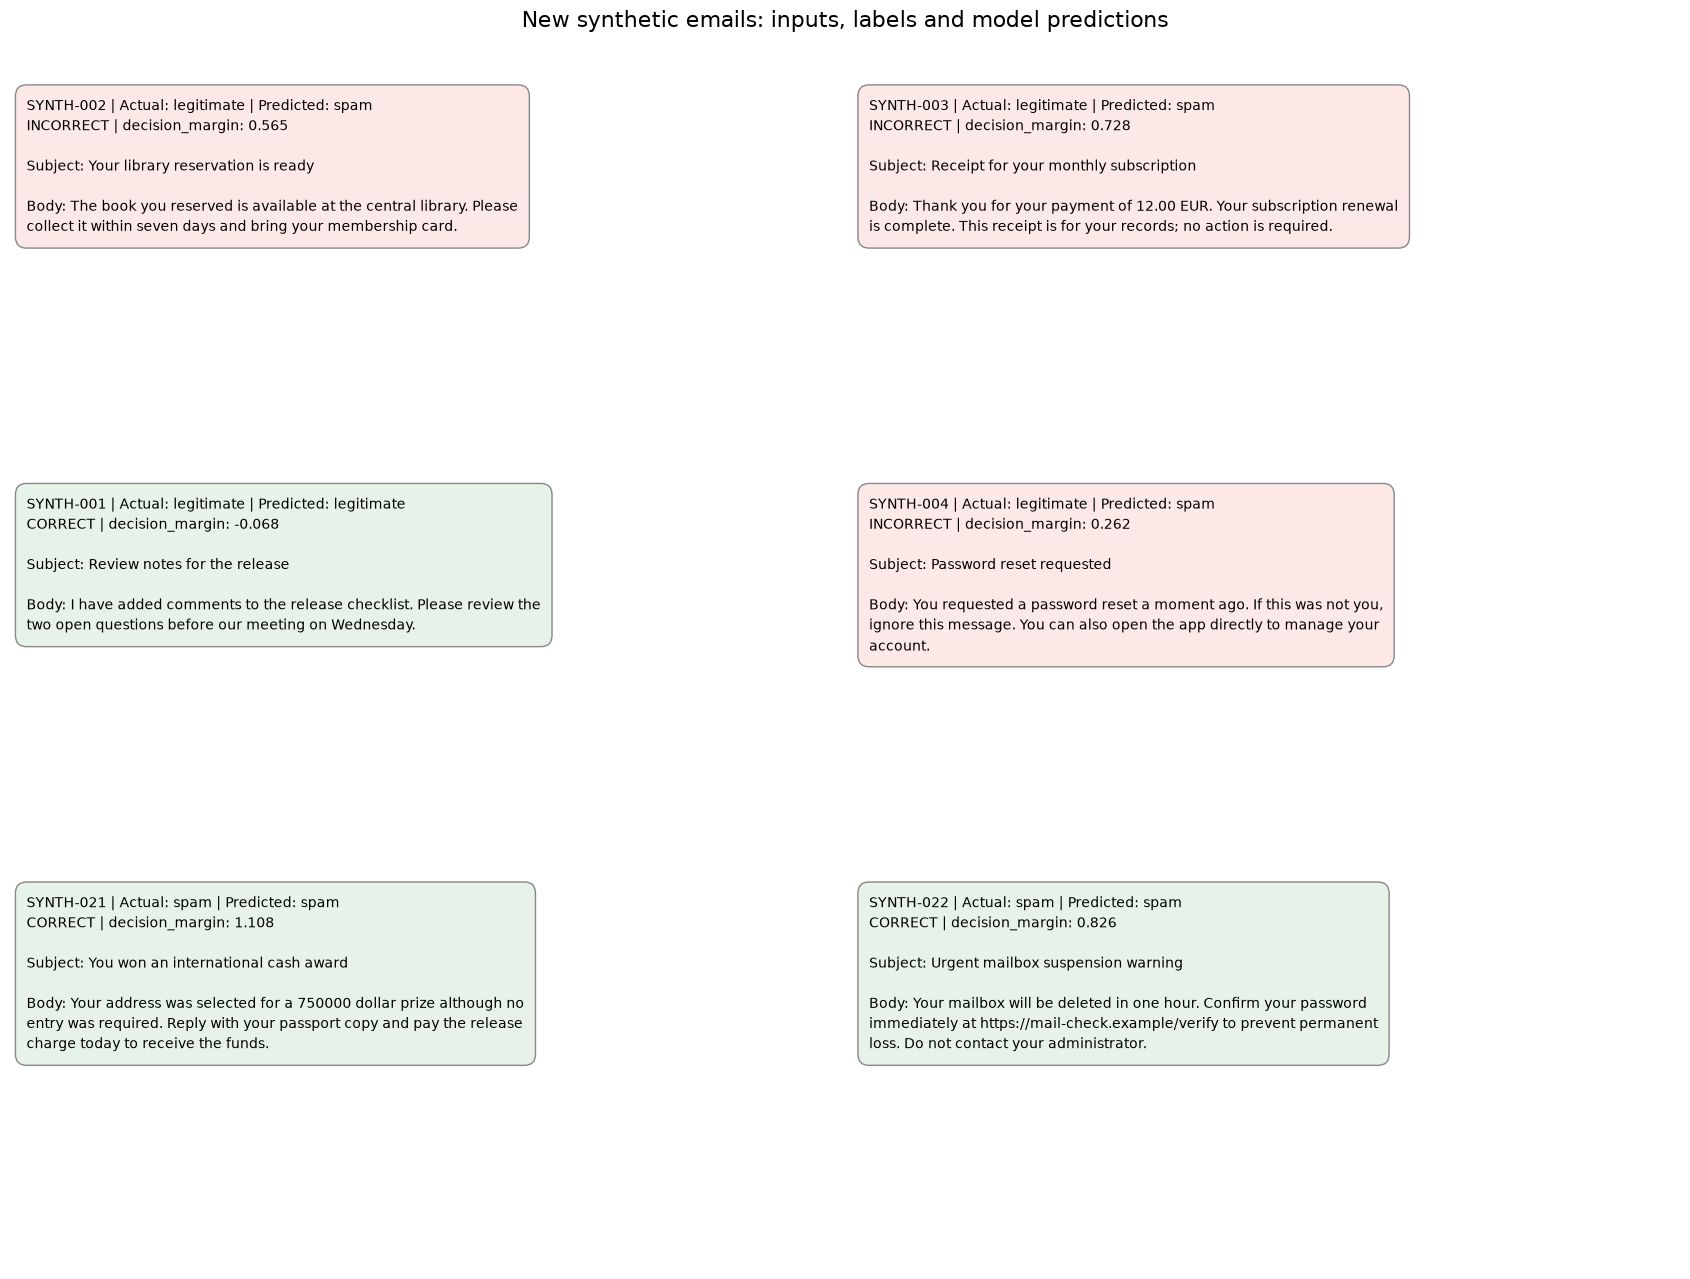

In [12]:
import textwrap
selected_indices = list(synthetic_predictions.index[~synthetic_predictions.correct][:2])
for actual in ["legitimate", "spam"]:
    candidates = [i for i in synthetic_predictions.index[synthetic_predictions.actual_label.eq(actual)]
                  if i not in selected_indices]
    selected_indices.extend(candidates[:2])
for i in synthetic_predictions.index:
    if len(selected_indices) >= min(6, len(synthetic_predictions)):
        break
    if i not in selected_indices:
        selected_indices.append(i)
selected_indices = selected_indices[:6]
fig, axes = plt.subplots(3, 2, figsize=(17, 13))
for ax in axes.flat:
    ax.set_axis_off()
for ax, (_, row) in zip(axes.flat, synthetic_predictions.loc[selected_indices].iterrows()):
    correct = bool(row.correct)
    color = "#e7f3e8" if correct else "#fce8e6"
    header = f"{row.message_id} | Actual: {row.actual_label} | Predicted: {row.prediction}"
    content = (header + "\n" + ("CORRECT" if correct else "INCORRECT")
        + f" | {row.score_type}: {row.spam_score:.3f}\n\n"
        + textwrap.fill("Subject: " + row.subject, width=72)
        + "\n\n" + textwrap.fill("Body: " + row.body, width=72))
    ax.text(0.02, 0.98, content, transform=ax.transAxes, va="top", ha="left",
            fontsize=10, linespacing=1.45,
            bbox={"boxstyle": "round,pad=0.8", "facecolor": color, "edgecolor": "#888888"})
fig.suptitle("New synthetic emails: inputs, labels and model predictions", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
